# Continuum Memory Systems: Multi-Frequency Memory Blocks for Reduced Forgetting in Transformers
**Final Project** |
**Coding Pipeline** |
**T. Hendricks**

PAPER: https://arxiv.org/pdf/2512.24695

Coding Pipeline Plan:
* Read in and format dataset.
* Create continual learning experiment function that contains sequential training and testing.
* Setup base model.
* Run experiment on base model. Expect to see catastrophic forgetting.
* Create CMS block class.
* Replace FFN/MLP in structure of base model with CMS block.
* Run experiment on updated model. Expect to see better performance than base model.
* Analysis: compare and contrast performance of both models.


In [1]:
import torch
from datasets import load_dataset
from collections import Counter
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import pandas as pd
import matplotlib.pyplot as plt

BERT_MODEL = 'distilbert/distilbert-base-uncased'

## Setup Dataset

- CLINIC150 dataset to download directly and save file: https://archive.ics.uci.edu/dataset/570/clinc150
- huggingface route of getting the data: https://huggingface.co/datasets/clinc/clinc_oos
- classification dataset, will use an encoder-only model
- Original paper for CLINIC150: https://arxiv.org/pdf/1909.02027
- Github for clinic150: https://github.com/clinc/oos-eval/blob/master/data/domains.json

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
if torch.cuda.is_available():
  print(torch.cuda.get_device_name(0))

cuda
NVIDIA A100-SXM4-40GB


In [3]:
# mount drive

from google.colab import drive

drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/Transformers_Final_Project"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
dataset = load_dataset("clinc_oos", "plus") # plus is full dataset

print(dataset)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


DatasetDict({
    train: Dataset({
        features: ['text', 'intent'],
        num_rows: 15250
    })
    validation: Dataset({
        features: ['text', 'intent'],
        num_rows: 3100
    })
    test: Dataset({
        features: ['text', 'intent'],
        num_rows: 5500
    })
})


In [5]:
# let's peak into the data

for i, dp in enumerate(dataset['train']):
  print(dp)
  if i == 5:
    break

{'text': 'what expression would i use to say i love you if i were an italian', 'intent': 61}
{'text': "can you tell me how to say 'i do not speak much spanish', in spanish", 'intent': 61}
{'text': "what is the equivalent of, 'life is good' in french", 'intent': 61}
{'text': "tell me how to say, 'it is a beautiful morning' in italian", 'intent': 61}
{'text': 'if i were mongolian, how would i say that i am a tourist', 'intent': 61}
{'text': "how do i say 'hotel' in finnish", 'intent': 61}


In [6]:
# let's look at the features of the dataset
dataset['train'].features

{'text': Value('string'),
 'intent': ClassLabel(names=['restaurant_reviews', 'nutrition_info', 'account_blocked', 'oil_change_how', 'time', 'weather', 'redeem_rewards', 'interest_rate', 'gas_type', 'accept_reservations', 'smart_home', 'user_name', 'report_lost_card', 'repeat', 'whisper_mode', 'what_are_your_hobbies', 'order', 'jump_start', 'schedule_meeting', 'meeting_schedule', 'freeze_account', 'what_song', 'meaning_of_life', 'restaurant_reservation', 'traffic', 'make_call', 'text', 'bill_balance', 'improve_credit_score', 'change_language', 'no', 'measurement_conversion', 'timer', 'flip_coin', 'do_you_have_pets', 'balance', 'tell_joke', 'last_maintenance', 'exchange_rate', 'uber', 'car_rental', 'credit_limit', 'oos', 'shopping_list', 'expiration_date', 'routing', 'meal_suggestion', 'tire_change', 'todo_list', 'card_declined', 'rewards_balance', 'change_accent', 'vaccines', 'reminder_update', 'food_last', 'change_ai_name', 'bill_due', 'who_do_you_work_for', 'share_location', 'internat

In [7]:
label_names_original_data = dataset['train'].features['intent'].names
print(f'There are {len(label_names_original_data)} intent labels.')
for name in label_names_original_data:
  if 'oos' == name:
    print('We need to remove oos intent from the data.')


There are 151 intent labels.
We need to remove oos intent from the data.


In [8]:
# filter out out-of-scope ('oos') data

oos_index = dataset['train'].features['intent'].names.index('oos')
print(f'oos intent num label: {oos_index}')

dataset = dataset.filter(lambda x: x["intent"] != oos_index)

# check filtering worked as expected on all subsets

assert len(dataset['train'].filter(lambda x: x['intent'] == oos_index)) == 0
assert len(dataset['test'].filter(lambda x: x['intent'] == oos_index)) == 0
assert len(dataset['validation'].filter(lambda x: x['intent'] == oos_index)) == 0

print(f'oos rows are filtered out of the dataset')

oos intent num label: 42
oos rows are filtered out of the dataset


In [9]:
# Need to remap intent index labels to be continuous (0-149)

unique_labels = sorted(set(dataset['train']['intent']))
print(f'Notice that {oos_index} is missing: {unique_labels}')

label_remap = {}
for new_i, old_label_num in enumerate(unique_labels):
  label_remap[old_label_num] = new_i

def remap_labels(datapoint):
  datapoint['intent'] = label_remap[datapoint['intent']]
  return datapoint

dataset = dataset.map(remap_labels)

UNIQUE_LABEL_NUMS = sorted(set(dataset['train']['intent']))
print(f'\nAfter remap, should be continuous from 0-149: {UNIQUE_LABEL_NUMS}')

expected_labels_list = [i for i in range(150)]
assert expected_labels_list == sorted(set(dataset['train']['intent']))
assert expected_labels_list == sorted(set(dataset['test']['intent']))
assert expected_labels_list == sorted(set(dataset['validation']['intent']))

NUM_INTENTS = len(UNIQUE_LABEL_NUMS)
assert NUM_INTENTS == 150

Notice that 42 is missing: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150]

After remap, should be continuous from 0-149: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 7

In [10]:
# set label names var excluding oos since we filtered it out

invert_remap = {v: k for k, v in label_remap.items()}
# invert_remap[new_index] --> original_index

LABEL_NAMES = [label_names_original_data[invert_remap[i]] for i in range(150)]

assert 'oos' not in LABEL_NAMES

In [11]:
# The following dict comes from paper gihub. Link at top Setup Dataset section above.

DOMAIN_TO_INTENTS = {
    "banking": [
        "freeze_account",
        "routing",
        "pin_change",
        "bill_due",
        "pay_bill",
        "account_blocked",
        "interest_rate",
        "min_payment",
        "bill_balance",
        "transfer",
        "order_checks",
        "balance",
        "spending_history",
        "transactions",
        "report_fraud"
    ],
    "credit_cards": [
        "replacement_card_duration",
        "expiration_date",
        "damaged_card",
        "improve_credit_score",
        "report_lost_card",
        "card_declined",
        "credit_limit_change",
        "apr",
        "redeem_rewards",
        "credit_limit",
        "rewards_balance",
        "application_status",
        "credit_score",
        "new_card",
        "international_fees"
    ],
    "kitchen_and_dining": [
        "food_last",
        "confirm_reservation",
        "how_busy",
        "ingredients_list",
        "calories",
        "nutrition_info",
        "recipe",
        "restaurant_reviews",
        "restaurant_reservation",
        "meal_suggestion",
        "restaurant_suggestion",
        "cancel_reservation",
        "ingredient_substitution",
        "cook_time",
        "accept_reservations"
    ],
    "home": [
        "what_song",
        "play_music",
        "todo_list_update",
        "reminder",
        "reminder_update",
        "calendar_update",
        "order_status",
        "update_playlist",
        "shopping_list",
        "calendar",
        "next_song",
        "order",
        "todo_list",
        "shopping_list_update",
        "smart_home"
    ],
    "auto_and_commute": [
        "current_location",
        "oil_change_when",
        "oil_change_how",
        "uber",
        "traffic",
        "tire_pressure",
        "schedule_maintenance",
        "gas",
        "mpg",
        "distance",
        "directions",
        "last_maintenance",
        "gas_type",
        "tire_change",
        "jump_start"
    ],
    "travel": [
        "plug_type",
        "travel_notification",
        "translate",
        "flight_status",
        "international_visa",
        "timezone",
        "exchange_rate",
        "travel_suggestion",
        "travel_alert",
        "vaccines",
        "lost_luggage",
        "book_flight",
        "book_hotel",
        "carry_on",
        "car_rental"
    ],
    "utility": [
        "weather",
        "alarm",
        "date",
        "find_phone",
        "share_location",
        "timer",
        "make_call",
        "calculator",
        "definition",
        "measurement_conversion",
        "flip_coin",
        "spelling",
        "time",
        "roll_dice",
        "text"
    ],
    "work": [
        "pto_request_status",
        "next_holiday",
        "insurance_change",
        "insurance",
        "meeting_schedule",
        "payday",
        "taxes",
        "income",
        "rollover_401k",
        "pto_balance",
        "pto_request",
        "w2",
        "schedule_meeting",
        "direct_deposit",
        "pto_used"
    ],
    "small_talk": [
        "who_made_you",
        "meaning_of_life",
        "who_do_you_work_for",
        "do_you_have_pets",
        "what_are_your_hobbies",
        "fun_fact",
        "what_is_your_name",
        "where_are_you_from",
        "goodbye",
        "thank_you",
        "greeting",
        "tell_joke",
        "are_you_a_bot",
        "how_old_are_you",
        "what_can_i_ask_you"
    ],
    "meta": [
        "change_speed",
        "user_name",
        "whisper_mode",
        "yes",
        "change_volume",
        "no",
        "change_language",
        "repeat",
        "change_accent",
        "cancel",
        "sync_device",
        "change_user_name",
        "change_ai_name",
        "reset_settings",
        "maybe"
    ]
}

In [12]:
# invert for faster lookup later
INTENT_TO_DOMAIN = {
    intent: domain # map intent to domain
    for domain, intents_list in DOMAIN_TO_INTENTS.items() # (domain, intent_list)
    for intent in intents_list
}

assert set(INTENT_TO_DOMAIN.keys()) == set(LABEL_NAMES), \
    f"Mismatch: {set(LABEL_NAMES) - set(INTENT_TO_DOMAIN.keys())} missing from domain map"

In [13]:
# add new column for domain

def add_domain_col(datapoint):
  # get the intent index for the given datapoint
  dp_intent_index = datapoint['intent']

  # get the name of the intent from the index
  dp_intent_name = LABEL_NAMES[dp_intent_index]

  # replace the intent index value int the intent column with the intent name on the datapoint
  datapoint['intent_name'] = dp_intent_name

  # get domain
  dp_domain = INTENT_TO_DOMAIN[dp_intent_name]

  # add new col for domain on the datapoint
  datapoint['domain'] = dp_domain

  return datapoint

# map: "Apply a function to all the examples in the table (individually or in batches) and update the table"
dataset = dataset.map(add_domain_col)



In [14]:
# check that data updated as expected
for i in range(5):
  print(dataset['train'][i])

{'text': 'what expression would i use to say i love you if i were an italian', 'intent': 60, 'intent_name': 'translate', 'domain': 'travel'}
{'text': "can you tell me how to say 'i do not speak much spanish', in spanish", 'intent': 60, 'intent_name': 'translate', 'domain': 'travel'}
{'text': "what is the equivalent of, 'life is good' in french", 'intent': 60, 'intent_name': 'translate', 'domain': 'travel'}
{'text': "tell me how to say, 'it is a beautiful morning' in italian", 'intent': 60, 'intent_name': 'translate', 'domain': 'travel'}
{'text': 'if i were mongolian, how would i say that i am a tourist', 'intent': 60, 'intent_name': 'translate', 'domain': 'travel'}


In [15]:
# check how many datapoints are in each domain
# should be 10 domains, with equal num of rows
domain_counts = Counter(dataset['train']['domain'])
print('Train examples per domain:')
for domain, count in sorted(domain_counts.items()):
    print(f'  {domain}: {count}')

print('\nTest examples per domain:')
for domain, count in sorted(Counter(dataset['test']['domain']).items()):
    print(f'  {domain}: {count}')

print('\nValidation examples per domain:')
for domain, count in sorted(Counter(dataset['validation']['domain']).items()):
    print(f'  {domain}: {count}')

Train examples per domain:
  auto_and_commute: 1500
  banking: 1500
  credit_cards: 1500
  home: 1500
  kitchen_and_dining: 1500
  meta: 1500
  small_talk: 1500
  travel: 1500
  utility: 1500
  work: 1500

Test examples per domain:
  auto_and_commute: 450
  banking: 450
  credit_cards: 450
  home: 450
  kitchen_and_dining: 450
  meta: 450
  small_talk: 450
  travel: 450
  utility: 450
  work: 450

Validation examples per domain:
  auto_and_commute: 300
  banking: 300
  credit_cards: 300
  home: 300
  kitchen_and_dining: 300
  meta: 300
  small_talk: 300
  travel: 300
  utility: 300
  work: 300


In [16]:
# Need to tokenize data for model to consume
tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)

In [17]:
# before tokenization, let's check out the max length of text --> for padding
lengths = [len(tokenizer(t)['input_ids']) for t in dataset['train']['text']]
print(f'Max token len in train: {max(lengths)}')

lengths = [len(tokenizer(t)['input_ids']) for t in dataset['test']['text']]
print(f'Max token len in test: {max(lengths)}')

lengths = [len(tokenizer(t)['input_ids']) for t in dataset['validation']['text']]
print(f'Max token len in validation: {max(lengths)}')

Max token len in train: 33
Max token len in test: 30
Max token len in validation: 29


In [18]:
# do the tokenization

def tokenize_datapoint(datapoint):
  return tokenizer(
      datapoint['text'],
      max_length = 40, # CLINC150 utterances are short so safe cutoff
      padding="max_length", # ensures all sequences are the same len
      truncation = True # if len(text)>max_length
  )

dataset = dataset.map(tokenize_datapoint, batched=True) # batched is an efficency thing here

In [19]:
# should see new columns from tokenizer --> input_ids, token_type_ids, attention_mask

print(dataset['train'][0])

{'text': 'what expression would i use to say i love you if i were an italian', 'intent': 60, 'intent_name': 'translate', 'domain': 'travel', 'input_ids': [101, 2054, 3670, 2052, 1045, 2224, 2000, 2360, 1045, 2293, 2017, 2065, 1045, 2020, 2019, 3059, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


In [20]:
# need to batch data with DataLoader AND need to seperate it by domains

BATCH_SIZE = 32
DOMAINS = sorted(set(dataset['train']['domain']))

train_domains_batched = {}
test_domains_batched = {}
validation_domains_batched = {}

for domain in DOMAINS:

  # filter subsets to current domain
  all_train_for_cur_domain = dataset['train'].filter(lambda x, d=domain: x['domain'] == d)
  all_test_for_cur_domain = dataset['test'].filter(lambda x, d=domain: x['domain'] == d)
  all_val_for_cur_domain = dataset['validation'].filter(lambda x, d=domain: x['domain'] == d)

  # set format to be compatable with DataLoaders --> torch
  all_train_for_cur_domain = all_train_for_cur_domain.with_format('torch')
  all_test_for_cur_domain = all_test_for_cur_domain.with_format('torch')
  all_val_for_cur_domain = all_val_for_cur_domain.with_format('torch')

  # batch each subset

  train_domains_batched[domain] = torch.utils.data.DataLoader(
      dataset=all_train_for_cur_domain,
      batch_size=BATCH_SIZE,
      shuffle=True
  )

  test_domains_batched[domain] = torch.utils.data.DataLoader(
      dataset=all_test_for_cur_domain,
      batch_size=BATCH_SIZE,
      shuffle=False
  )

  validation_domains_batched[domain] = torch.utils.data.DataLoader(
      dataset=all_val_for_cur_domain,
      batch_size=BATCH_SIZE,
      shuffle=False
  )


In [21]:
# Test that it split as expected

assert train_domains_batched.keys() == test_domains_batched.keys()
assert train_domains_batched.keys() == validation_domains_batched.keys()
assert len(train_domains_batched) == len(DOMAINS)
assert len(test_domains_batched) == len(DOMAINS)
assert len(validation_domains_batched) == len(DOMAINS)

for domain in DOMAINS:
  assert len(train_domains_batched[domain].dataset) == 1500
  assert len(test_domains_batched[domain].dataset) == 450
  assert len(validation_domains_batched[domain].dataset) == 300


In [22]:
# let's take a peak at what a batch looks like
one_domain_batch = next(iter(train_domains_batched['banking']))
print(one_domain_batch)

assert len(one_domain_batch['input_ids']) == BATCH_SIZE

{'text': ['how much do i owe in bills', 'what would the interest rate at wells fargo be', 'can you notify the bank to put a stop on my account', "what's my current interest rate, if you could look", "what's my total net worth in all of my bank accounts", 'i would like to request that more checkbooks be mailed to me', 'what did i spend at the grocery store yesterday', 'i need a recent transaction looked into', 'how much is my cable bill for', 'i need the dollar amount due on my verizon bill, please', 'looking at january, show all wine purchases', 'show me the transactions made on my business card for supplies last quarter', 'how can i stop transactions on my account', 'can you tell me the total cost of my bills please', "when's my heater bill due", 'what have car repairs ran me this month', 'i need to report fraudulent activity on my mastercard', 'put a block on my amalgamated bank account right now', 'what is the minimum i can pay for the gas bill', "why isn't it letting me into my ban

## Create Continual Learning Experiment

Idea for how the training and testing will done:

After training Domain 1:
* test Domain1 --> record accuracy

After training Domain 2:
* test Domain1 --> record accuracy <-- watch for forgetting
* test Domain2 --> record accuracy

After training Domain 3:
* test Domain1 --> record accuracy <-- watch for forgetting
* test Domain2 --> record accuracy <-- watch for forgetting
* test Domain3 --> record accuracy

... etc.






In [23]:
def train(classifier_model, batched_training_data, optimizer, _device, learning_rate=5e-4, num_epochs=20, include_print=True):

    # conditional: new optimizer OR same optimizer that gain momentum between training runs
    if optimizer == None: # create new optimizer each time train is called
      optimizer = torch.optim.AdamW(params=classifier_model.parameters(), lr=learning_rate)

    classifier_model = classifier_model.to(_device)

    losses = []
    for epoch in range(num_epochs):
        epoch_loss = 0.0
        correct = 0
        total = 0
        classifier_model.train()
        for batch in batched_training_data:

            tokenized_text = batch['input_ids'].to(_device)
            mask = batch['attention_mask'].to(_device)
            idx_labels = batch['intent'].to(_device)

            # zero optimizer to start
            optimizer.zero_grad()

            # forward
            outputs = classifier_model(
                input_ids=tokenized_text,
                attention_mask=mask,
                labels=idx_labels
            )

            # get loss and logits from module
            loss = outputs.loss
            logits = outputs.logits

            # back propagation
            loss.backward()
            # increment optimizer
            optimizer.step()

            # stats
            epoch_loss += loss.item()
            predictions = torch.argmax(logits, dim=-1)
            correct += (predictions == idx_labels).sum().item()
            total += idx_labels.size(0)

        # save avg loss per epoch
        avg_loss = epoch_loss / len(batched_training_data)
        losses.append(avg_loss)
        accuracy = correct / total
        if include_print:
            print(f'Epoch {epoch+1}, Avg loss: {avg_loss:.3f}, Accuracy: {accuracy:.4f}')

    print('Training complete!')
    return losses

In [24]:
def evaluate(_classifier_model, _batched_test_data, _device):

    _classifier_model.eval()
    correct = 0
    total = 0
    with torch.no_grad(): # no gradient computation
        for batch in _batched_test_data:
            tokenized_text = batch['input_ids'].to(_device)
            mask = batch['attention_mask'].to(_device)
            idx_labels = batch['intent'].to(_device)

            output = _classifier_model(
                    input_ids=tokenized_text,
                    attention_mask=mask
            )

            logits = output.logits

            # argmax along rows: dim=1; argmax along cols: dim=0
            preds = torch.argmax(logits, dim=-1)

            correct += (preds == idx_labels).sum().item()
            total += idx_labels.size(0) # batch size

    accuracy = (correct / total) * 100
    return accuracy

In [25]:
def continual_learning_experiment(classifier_model,
                                    batched_training_data,
                                    batched_test_data,
                                    _device,
                                    has_shared_optimizer=True,
                                    learning_rate=5e-4,
                                    num_epochs=20,
                                    include_print=True
                                    ):

  if has_shared_optimizer: # same optimizer between domains
    optimizer = torch.optim.AdamW(params=classifier_model.parameters(), lr=learning_rate)
  else: # new optimizer for each train call
    optimizer = None

  results = {}

  for i, cur_domain in enumerate(DOMAINS):
    print(f'Training on domain {i+1}/{len(DOMAINS)}: {cur_domain}')

    # train all batched data related to the current domain only
    losses = train(
        classifier_model,
        batched_training_data[cur_domain],
        optimizer,
        _device,
        learning_rate,
        num_epochs,
        include_print
    )

    # evaluate on all domains up to and including current
    results[cur_domain] = {}
    # track losses that happened for this domain during training
    results[cur_domain]['losses'] = losses
    # capture acc right after training
    results[cur_domain]['baseline_acc'] = evaluate(classifier_model, batched_test_data[cur_domain], _device)
    for domain in DOMAINS[:i+1]:
      acc = evaluate(classifier_model, batched_test_data[domain], _device)

      results[cur_domain][domain] = acc

      print(f'Accuracy on {domain}: {acc:.2f}')

  return results


## Setup Evaluation Functions

### Create Backward Transfer Function

This paper cites BWT as metric to measure continual learning between models: https://arxiv.org/pdf/1706.08840

$$BWT = \frac{1}{T-1} \sum_{i=1}^{T-1} \left( R_{T,i} - R_{i,i} \right)$$

Where:
- $T$ = total number of tasks
- $R_{T,i}$ = accuracy on task $i$ after training on all $T$ tasks
- $R_{i,i}$ = accuracy on task $i$ immediately after training on task $i$

In [26]:
def backward_transfer(R):
    """
    Compute Backward Transfer (BWT) from an accuracy matrix.

    BWT measures how much learning future tasks helps or hurts performance
    on previously learned tasks. Negative BWT indicates forgetting.

    Params:
        R list[list[float]]: A T×T accuracy matrix where R[i][j] is the accuracy on task j
           after training on task i. Only the lower triangle is used.
           (0-indexed, so R[i][i] is accuracy on task i right after training it)

    Returns:
        BWT score as a float. Negative = forgetting, Positive = transfer.
    """
    T = len(R)
    if T < 2:
        raise ValueError("Need at least 2 tasks to compute BWT.")

    bwt = sum(R[T - 1][i] - R[i][i] for i in range(T - 1)) / (T - 1)
    return bwt

### Create Average Accuracy Function

This paper cites ACC as metric to measure continual learning between models: https://arxiv.org/pdf/1706.08840

After the model has sequentially learned all T domains, it gets evaluated on every task's test set and the average of those scores is recorded.

$$ACC = \frac{1}{T} \sum_{i=1}^{T} R_{T,i}$$

Where:
- $T$ = total number of tasks
- $R_{T,i}$ = accuracy on task $i$ after training on all $T$ tasks

In [27]:
def average_accuracy(R):
    """
    Compute Average Accuracy (ACC) after sequential training on all T tasks.

    ACC measures the model's overall retention across all tasks once the
    full training sequence is complete.

    Params:
        R list[list[float]]: A T×T accuracy matrix where R[i][j] is the accuracy on task j
           after training on task i. Only the final row is used.
           (0-indexed, so R[T-1][i] is accuracy on task i after all training)

    Returns:
        ACC score as a float in [0, 1].
    """

    T = len(R)
    if T < 1:
        raise ValueError("Need at least 1 task to compute ACC.")

    acc = sum(R[T - 1][i] for i in range(T)) / T
    return acc

### Average Accuracy of the Diagonal

The purpose of this is to calculate the performance of the modal on the prediction accuarcy for the domain it was just trained on. While this does not measure forgetting, I felt that it was a baseline metric to have so we can see if the model structure impacts its ability to learn on the current topic (not continual measure).

(I did not get this from a paper, it was just my idea to include it).

$$\text{ADA} = \frac{1}{T} \sum_{i=1}^{T} R_{i,i}$$

Where:
- $T$ = total number of tasks
- $R_{i,i}$ = accuracy on task $i$ immediately after training on task $i$
- Let ADA stand for "average diagonal accuracy" in matrix R

In [28]:
def diagonal_accuracy(R) -> float:
    """
    Compute average diagonal accuracy from R matrix.
    R[i][i] = accuracy on task i immediately after training on task i.
    Averages across all tasks to give a single score representing
    how well the model learned each domain at its peak.

    Params:
        R: T x T accuracy matrix

    Returns:
        Average diagonal accuracy as a float
    """
    T = len(R)
    return sum(R[i][i] for i in range(T)) / T

## Baseline Model

Comments on why I chose this baseline model:
- Google NL paper uses llama-3-8b and llama-3 as the base model. These are decoder only models.
- Could be nteresting to do my research on an encoder only model if I use the Clinic50 dataset since it is a classification dataset (and is a dataset used in the Google NL paper too). I could show if CMS architecture in place of MLP is better to reduce forgetting on classification tasks in a sequential training environment.
  - This paper tested 3 encoder only models on Clinic50 dataset. DistilBERT was found to be efficient and accuracy similar to best performing model. https://ieeexplore.ieee.org/document/11118772

In [29]:
# AutoModelForSequenceClassification adds the final linear layer for classification of labels
base_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL,
    num_labels = NUM_INTENTS, # adds classification head
    device_map=device
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [30]:
%%time

# run continual learning experiment and store results

base_results = continual_learning_experiment(
    classifier_model=base_model,
    batched_training_data=train_domains_batched,
    batched_test_data=test_domains_batched,
    _device=device,
    has_shared_optimizer=True,
    learning_rate=2e-5,
    num_epochs=10
  )


Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.449, Accuracy: 0.1973
Epoch 2, Avg loss: 2.953, Accuracy: 0.7133
Epoch 3, Avg loss: 1.428, Accuracy: 0.9680
Epoch 4, Avg loss: 0.584, Accuracy: 0.9860
Epoch 5, Avg loss: 0.265, Accuracy: 0.9960
Epoch 6, Avg loss: 0.158, Accuracy: 0.9967
Epoch 7, Avg loss: 0.103, Accuracy: 0.9987
Epoch 8, Avg loss: 0.071, Accuracy: 0.9987
Epoch 9, Avg loss: 0.053, Accuracy: 0.9993
Epoch 10, Avg loss: 0.041, Accuracy: 1.0000
Training complete!
Accuracy on auto_and_commute: 98.00
Training on domain 2/10: banking
Epoch 1, Avg loss: 4.605, Accuracy: 0.0773
Epoch 2, Avg loss: 2.434, Accuracy: 0.5140
Epoch 3, Avg loss: 0.885, Accuracy: 0.9333
Epoch 4, Avg loss: 0.293, Accuracy: 0.9887
Epoch 5, Avg loss: 0.140, Accuracy: 0.9973
Epoch 6, Avg loss: 0.088, Accuracy: 0.9980
Epoch 7, Avg loss: 0.063, Accuracy: 0.9993
Epoch 8, Avg loss: 0.050, Accuracy: 0.9993
Epoch 9, Avg loss: 0.040, Accuracy: 0.9993
Epoch 10, Avg loss: 0.035, Accuracy: 0.9993
Training

### Brief Visualization of Continual Learning Results

In [31]:
def results_to_pivot(results, domains):
    rows = []
    for train_domain, evals in results.items():
        for eval_domain, acc in evals.items():
            if eval_domain not in ['losses', 'baseline_acc', 'grad_norms']:
                rows.append({
                    'trained_on': train_domain,
                    'evaluated_on': eval_domain,
                    'accuracy': acc
                })

    df = pd.DataFrame(rows)

    # formatting of trained vs evaluated results in table
    pivot = df.pivot(index='trained_on', columns='evaluated_on', values='accuracy')
    pivot = pivot.reindex(index=domains, columns=domains)

    return pivot.style\
        .background_gradient(cmap='RdBu', axis=None, vmin=0, vmax=100)\
        .format('{:.3f}', na_rep='-')\
        .set_caption('Continual Learning Accuracy Matrix (%)')

In [32]:
results_to_pivot(base_results, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,98.000,-,-,-,-,-,-,-,-,-
banking,0.000,94.667,-,-,-,-,-,-,-,-
credit_cards,0.000,0.000,94.444,-,-,-,-,-,-,-
home,0.000,0.000,0.000,94.444,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.000,92.667,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.000,96.222,-,-,-,-
small_talk,0.000,0.000,0.000,0.000,0.000,0.000,96.444,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,1.556,98.222,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,97.556,-


## Baseline Model + CMS

In [33]:
# need to load a fresh BERT instance
cms_bert = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL,
    num_labels = NUM_INTENTS,
    device_map=device
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [34]:
# view DistilBERT architecture
print(cms_bert) # currently no CMS, should see FFN

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


A few things to consider when building:
- CMS block needs to be a drop-in replacement of `FFN` considering input and output dimensions: 768 --> 768
  - Therefore, we know that CMS block we are building must take (batch, seq_len, 768) and return (batch, seq_len, 768).
- `FFN` architecture:
  - `dropout` --> `linear_1` --> `linear_2` --> `GELU activation`
- `output_layer_norm` sits outside the `FFN`, so this will not need to be addressed in CMS block.

Some notes on CMS from paper:
- CMS is a chain of MLP blocks
  - MLP blocks in CMS can be viewed as storage for things that the model would have catastophic forgetting of. When a later MLP block is updated, it will probably forget what it learned but that knowledge is stored in the previous MLP block - thus, helping the model to not forget.
- Variants:
  - Nested CMS
  - Sequential CMS
  - Independent CMS
- Frequency (from definition 2)
  - = number of updates per unit of time.
  - Thus, inc freq == inc in num of param updates
- CMS fundamentals (regardless of variant):
  1. MLP chain runs sequentially --> output of block n feeds into block n+1 etc...
  2. MLP parameters update every $C^{(l)}$
- Frequency and chunk size (C) have an inverse relationship
  - ie: a block that updates every step has the highest freq; a block that udpates every 4 steps has the lowest freq.
  - Higher frequency == smaller chunk size == updates more often == faster, task-specific memory
  - Lower frequency == larger chunk size == updates less often == slower, persistent memory
- The paper claims that applying the above ideas to the standard transformer with FFN has a frequency of 0 - meaning that its weights do not update (frozen), and thus it is failing to learn.
  - However, in consideration of the experiment we are doing in this notebook, we are doing full finetuning of DistilBert. Meaning that there are no frozen weights, the parameters are updated after each FFN, and thus we can infer this means that max frequency is being applied (update every step). In a continual learning environment, this is problematic bc it causes the model to experience catastropic forgetting as the constant parameter updates causes it to "overwrite" what it previously learning.
- We can reduce the loss in knowledge with CMS as it replaces the FFN with MLP blocks that update with a spectrum of frequencies, allowing the model at varying rates to update knowledge stored while also recalling past info it has learned.
  - We want frequency to vary between MLP blocks. Why? --> consider standard continual learning full finetuning, we can know that freqency is maxed (update every step) AND that the updates are linear (meaning fixed). If we made frequency fixed in our CMS block, then we would not be getting much lift in the changed implementation (still lineary, and thus, nearly equivalent results --> there would be no spectrum of memory timescales --> collapses CMS back into FFN). So, from that we know that we should have the frequency variable between chunks. The differentiation between frequencies is what creates the long-term/short-term memory distinction.
  



**More details on the math for CMS from the paper:**

Given input: $x = {x_1, ..., x_T }$

Forward pass. The output of the CMS chain can be formally written as:
$$\mathbf{y}_t = \text{MLP}^{(f_k)}\left(\text{MLP}^{(f_{k-1})}\left(\cdots\text{MLP}^{(f_1)}\left(\mathbf{x}_t\right)\right)\right)$$

Where parameter updates happen every $C^{(\ell)}$ steps:
$$C^{(\ell)} := \frac{\max_i C^{(i)}}{f_\ell}$$

Parameter update rule:

$$\theta^{(f_\ell)}_{i+1} = \theta^{(f_\ell)}_i - \begin{cases} \sum_{t=i-C^{(\ell)}}^{i} \eta^{(\ell)}_t f(\theta^{(f_\ell)}_t; x_t) & \text{if } i \equiv 0 \pmod{C^{(\ell)}} \\ 0 & \text{otherwise} \end{cases}$$

Where
- $\eta^{(\ell)}_t$ - learning rate for block $\ell$ at step $t$.
  - This implies that each block could have its own learning rate and that it changes overtime.
    - This is standard practice in training, not unique to CMS. The learning rate scheduler is the thing that changes the learning rate overtime based on the decay function (ie linear, cosine annelaing etc).
- $\theta^{(f_\ell)}$ - the parameters of the MLP block associated with frequency $f_\ell$ that get updated
- and $f(\theta^{(f_\ell)}_t; x_t)$ is the error component of an arbitrary optimizer (ie: gradient descent loss)
- Note that $f$ as a superscript is representative of frequency, and $f(\cdot)$ is representative of optimizer error function.

Parameter update is basically saying:
- Accumulate the optimizer's error signal over the last $C^{(\ell)}$ steps, scale by the learning rate, and subtract from the current parameters. But only do this every $C^{(\ell)}$ steps, otherwise leave the parameters unchanged.

Update frequency:
$$f_A = \text{number of updates per unit of time}$$




**Some key takeways from the math**

There is a difference between what happens in the forward and backward pass based on the above equations.

- Chaining is about the forward pass
  — Input flows through MLP block 1 → block 2 → ... → block k on every forward pass regardless of anything else.

- Update frequency is about the backward pass
  — whether a given block's parameters change after that forward pass. Block $\ell$ runs its forward pass every step, but its weights only get updated every $C^{(\ell)}$ steps.

Here is the idea:

```
1. forward pass through ALL blocks (chaining always happens)
2. compute loss
3. backward pass
4. Then for each block l:
    if step % C(l) == 0:
        optimizer.step() --> apply accumulated gradients --> weights change
        reset gradient with zero_grad()
    else:
        do nothing --> .grad keeps accumulating
```

Implementation detail from this:
- The parameters only change with `optimize.step()` is called on it. Until then, the weights stay frozen and the gradients continue to accumulate.
  - $C^{(\ell)}$ determines how many steps pass before call `optimizer.step()` on this block
- Design decisions point to consider:
  - Idea A: seperate optimizer per MLP block within CMS
    - Ie: within CMS we have say 3 MLP blocks, then there will be 3 optimizers init at the beginning which manages the parameters of that MLP across all 6 transfomer layers.
  - Idea B: single optimizer with manual gradient masking
    - One optimizer for all model params. There may be a higher risk of loosing accumulated gradients.

**What are the differences between the variants of CMS?**

All variants share the same CMS foundation discussed above.

What differes is:
- how they initalize the weights of each block
- and how MLP blocks are connected

1. Nested CMS
- Initial state of the MLP block in level s+1 is meta-learned in level s.
- At the end of each update step $C^{(\ell)}$ the value of memory will be reinitalized (meaning the block's weights get reset back to that meta-learned initialization).
  - This means that the final params from S are not directly used as S+1's weights. What transfers from S to S+1 is the meta-learned initialization, which is derived from S's context but is computed separately via the meta-learning objective (eq 72).

2. Sequential CMS
- Initial state of MLP blocks are all connected through backpropagation in the lowest frequency level.
  - It's a one-time meta-learning process that happens before continual learning begins.
  - I'm reading this as no re-initalization between chunks. The meta-learned init is the starting weights for the first block. After that, the output of the previous block is the input of the next block.

3. Independent CMS
- Same initalization process as sequential
- independent blocks with different context lengths and then combines them with an aggregation process to compute output

**Insight from section 7.3 of paper that changes our implementation**

- 7.3 Ad-hoc Level Stacking: Initializing CMS with Pre-Trained Models
- It said that that instead of needing a meta-learning phase to compute initalization of MLP blocks​, the initialization can come from the weights in the FFN of the existing model being modifyed.
- Why this works?
  - because in the Nested Learning framework, pre-trained weights already represent knowledge compressed at lowest frequency level, which is exactly what we want as a starting point for all blocks (sequential and independet variants this works cleanly).

**Design descision**:

- CMS Variant: Sequential CMS
- Number of blocks in CMS: 3 — minimal but meaningful spectrum of memory timescales
  - answer not stated in paper
- Chunk sizes: [1, 2, 4] — exponential increasing schedule, block 0 updates every step, block 1 every 2 steps, block 2 every 4 steps
  - answer not stated in paper
- Frequency ordering: increasing — faster blocks first, slower blocks last, consistent with paper's framing of short-term to long-term memory through the chain
- Initialization: copy DistilBERT's pre-trained FFN weights into each CMS block (Section 7.3) — no meta-learning loop needed
- Forward pass: sequential chaining every step, all blocks always run regardless of chunk size
- Update mechanism: separate optimizer per block, selective optimizer.step() called based on each block's chunk size
- Backward pass: gradients flow through all blocks every step unconditionally — frequency control only affects whether optimizer.step() is called
- Dropout: preserve DistilBERT's original dropout probability of 0.1 inside each block for consistency with the base model
- Hidden dimensions: match DistilBERT's original FFN dimensions
- Normalization: DistilBert has LayerNorm after FFN, will keep that and not add normalization inside CMS

Where needed, DistilBert source code was referenced: https://github.com/huggingface/transformers/blob/main/src/transformers/models/distilbert/modeling_distilbert.py

In [35]:
# Setup CMS foundation

class MLP(torch.nn.Module):
  """
  This is a single MLP block designed to sit within the CMS block.
  The internal architecture here mirrors DistilBert's FFN.
  While not handled in this class, this MLP is different in that it's weight updates will be controlled by a frequency variable.
  """

  def __init__(self, n_hidden=768, n_intermediate_hidden=3072, dropout=0.1):
    super().__init__()

    self.linearLayer1 = torch.nn.Linear(in_features=n_hidden, out_features=n_intermediate_hidden)
    self.linearLayer2 = torch.nn.Linear(in_features=n_intermediate_hidden, out_features=n_hidden)

    self.dropout = torch.nn.Dropout(p=dropout)

    self.gelu = torch.nn.GELU()

  def forward(self, x):
    x = self.linearLayer1(x)
    x = self.gelu(x)
    x = self.linearLayer2(x)
    x = self.dropout(x)

    return x

# num_blocks — how many MLP blocks are in the chain
# chunk_sizes — how often each block's optimizer gets stepped
class CMS(torch.nn.Module):
    """
    Continuum Memory System is made up of a chain of MLP blocks where each block's parameter updates are controlled by a chunk size,
    which defines how many steps pass between optimizer updates for that block.
    Blocks with smaller chunk sizes update more frequently (short-term memory) and
    blocks with larger chunk sizes update less frequently (long-term memory).
    """
    def __init__(self, chunk_sizes=None, num_blocks=3, n_hidden=768, n_intermediate_hidden=3072, dropout=0.1):
      super().__init__()

      if chunk_sizes==None:
        chunk_sizes = [1, 2, 4] # exponential
      self.chunk_sizes = chunk_sizes

      if len(chunk_sizes) != num_blocks:
        raise ValueError("The number of chunk sizes needs to match the number of blocks."
                         "The chunk sizes is what controls how often that specific block optimizer gets stepped")

      # CMS is built up of a chain of MLP blocks
      self.blocks = torch.nn.ModuleList([
          MLP(n_hidden, n_intermediate_hidden, dropout)
          for _ in range(num_blocks)
      ])

    def forward(self, x):
      for block in self.blocks:
        # Sequential variant: output from previous block is input to current block
        x = block(x)
      return x


We need to setup weight initalization for the MLP blocks. Based on section 7.3 in the paper, a straightforward and effective way to do this is by using the weights from the pretrained model from the FFN of each of its Transformer layers. While the output from the previou MLP block feeds into the input of the current MLP block, these blocks have a starting parameter that would be set by torch as random. Rather than having that, we are going to set their starting weights to be grounded in pretrained weights per transformer layer for better output.

In [36]:
# Setup CMS initalization

def initialize_cms_from_pretrained(cms_block, pretrained_ffn):
    """
    Initialize all MLP blocks in a CMS block with the weights from
    a pretrained DistilBERT FFN layer (Section 7.3).

    All MLP blocks in the CMS start from the same pretrained weights,
    giving them a stable and meaningful starting point rather than
    random initialization.

    Paramaters:
        cms_block: CMS instance whose MLP blocks will be initialized
        pretrained_ffn: the pretrained FFN from a DistilBERT transformer layer
    """
    with torch.no_grad():
        for mlp_block in cms_block.blocks:

            mlp_block.linearLayer1.weight.copy_(pretrained_ffn.lin1.weight)
            mlp_block.linearLayer1.bias.copy_(pretrained_ffn.lin1.bias)

            mlp_block.linearLayer2.weight.copy_(pretrained_ffn.lin2.weight)
            mlp_block.linearLayer2.bias.copy_(pretrained_ffn.lin2.bias)



In [37]:
# quick sanity check
cms_bert.distilbert.transformer.layer[0].ffn

FFN(
  (dropout): Dropout(p=0.1, inplace=False)
  (lin1): Linear(in_features=768, out_features=3072, bias=True)
  (lin2): Linear(in_features=3072, out_features=768, bias=True)
  (activation): GELUActivation()
)

Next, we need a function to swap the FFN block for CMS within DistilBert.

In [38]:
# swap function
def replace_ffn_with_cms_in_distilbert(_model, chunk_sizes=None, num_blocks=3):
  """
  The purpose of this function is to mutate (in place) the architecutre of DistilBert
  such that its FFN blocks are swapped with CMS blocks.
  """
  for i, layer in enumerate(_model.distilbert.transformer.layer):

    # 1. grab the pretrained FFN
    pretrained_ffn = layer.ffn

    # 2. create a new CMS block

    # must use these params bc initalizing CMS from pretrained FFN
    n_hidden=768
    n_intermediate_hidden=3072
    dropout=0.1

    cms_block = CMS(chunk_sizes, num_blocks, n_hidden, n_intermediate_hidden, dropout)

    # 3. initialize CMS from pretrained FFN
    initialize_cms_from_pretrained(cms_block, pretrained_ffn)

    # 4. replace the layer's FFN with the CMS block
    layer.ffn = cms_block


In [39]:
# run swap
replace_ffn_with_cms_in_distilbert(cms_bert)

# verify the swap worked - should see CMS in place of FFN
print(cms_bert)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): CMS(
            (blocks): ModuleList(
              (0-2)

Before I write the code to address the optimizers needed in this modified implementation of DistilBert with CMS blocks, let's briefly note the standard approach to optimizers and their significance:
- In a standard transformer setup, typically one optimizer instance manages all the model's parameters.
- The optimizer is configured in the train function before the training loop starts and it runs throughout training. It does not exist within the transfomer architecture.
- Gradients are computed by PyTorch's autograd engine during the backward pass and stored temporarily on each param. The optimizer is the thing that reads the gradient and uses that to update the model weights according to the optimizers update rule.
- During training, the backward pass computes the .grad attribute on each parameter. Then, the optimizer.step() which comes next will update the model weights. How is that update amount derived?
  - Gradient to optimizer to weight update.
  - Gradient tells you the direction and magnitude of the steepest increase in loss during the current backwards pass in the loop. The optimizer then uses that value to go in the opposite direction to reduce loss. The specific numeric impact that has on the weights is derived by that optimizers function and is scaled by the learning rate.
  - The gradient is the partial derivative of each weight parameter in the model. Therefore, it is the slope (vector) of the loss with respect to each weight parameter.
- Note that in the training loop the following happens:
  - optimizer.zero_grad() clears the gradients from the previous iteration
  - forward pass computes predictions
  - loss function compares predictions to actual values. It outputs a continuous scalar that measures how wrong the prediction was (loss). This value is mathematically derived based upon the loss function initalized before the training loop begins.
  - loss.backward() computes the gradients and stores the value on .grad attribute on each weight param
  - optimizer.step() updates each model weight according to gradient, optimizer function, and learning rate

Now for our implementation:

We need separate optimizers per CMS block so we can call optimizer.step() selectively based on chunk size. The structure will be:
- One optimizer for all non-CMS parameters (attention, embeddings, classifier head) — these always update every step. This is "normal" practice when training transformers. The difference comes in the next bullet point...
- One optimizer per MLP block index across all 6 CMS blocks — these update based on their chunk size

In [40]:
def optimizer_setup(_model, _learning_rate):

  # 1) set optimizer per MLP block across 6 transformer layers

  # assumes replace_ffn_with_cms_in_distilbert has already been called
  chunk_sizes = _model.distilbert.transformer.layer[0].ffn.chunk_sizes
  num_of_mlp_blocks_per_cms = len(chunk_sizes)

  mlp_block_optimizers = [] # len == num_of_mlp_blocks_per_cms; flat list
  # ex: [optimizer 0 for all mlp block 0 shared across 6 layers, optimizer 1 for all mlp block 1 shared across 6 layers, etc.]

  for i in range(num_of_mlp_blocks_per_cms): # per mlp block index

    # collect mlp block i's param for all 6 transfomer layers
    block_i_params = [] # 4 params per mlp block x 6 transformer layers = 24 parameters per mlp block
    for layer in _model.distilbert.transformer.layer: # in each transfomer layer
      for param in layer.ffn.blocks[i].parameters(): # grab learnable param
        # expected: linearLayer1.weight, linearLayer1.bias, linearLayer2.weight, linearLayer2.bias
        block_i_params.append(param)

    # set optimizer per mlp block in each transfomer layer
    optimizer_i = torch.optim.AdamW(params=block_i_params, lr=_learning_rate)
    mlp_block_optimizers.append(optimizer_i)
  # Note: total num cms params = num_blocks x num_params_per_mlp_block

  # 2) all non-CMS params share an optimizer
  non_cms_params = []
  for name, param in _model.named_parameters():
    if 'ffn' not in name:
      non_cms_params.append(param)
  base_optimizer = torch.optim.AdamW(params=non_cms_params, lr=_learning_rate)

  return mlp_block_optimizers, base_optimizer


### Modify train and continual learning functions

The next thing that needs to be done is to write an updated version of the training function since there will be differences in the way that parameters get updated. The following are the key changes that need to be made:
- init step counter and increment steps.
  - this was not needed in the regular trainer bc optimizer was stepped each time.
- Remove the single `optimizer.zero_grad()` at the start
- Keep the forward pass the same
- Keep loss.backward() the same
- Replace the single `optimizer.step()` with selective stepping based on chunk size
- Only call zero_grad() on blocks that just stepped
- Always step and zero_grad the base_optimizer
- Add conditional logic for dynamic number of epochs


In [41]:
def train_with_cms(classifier_model,
                   batched_training_data,
                   _device,
                   chunk_sizes=[1,2,4],
                   learning_rate=5e-4,
                   num_epochs=20,
                   include_print=True,
                   optimizers=None,
                   step=None,
                   patience=None,
                   min_delta=None
                   ):

    if optimizers is None:
      # init optimizers
      mlp_block_optimizers, base_optimizer = optimizer_setup(classifier_model, learning_rate)
    else:
      mlp_block_optimizers, base_optimizer = optimizers

    classifier_model = classifier_model.to(_device)

    if step is None:
      step = 1 # see markdown below this cell to explain init val

    # to experiment with dynamic epochs
    if patience is not None and min_delta is not None:
      best_loss = float('inf')
      best_acc = 0.0
      epochs_without_improvement = 0

    losses = []
    grad_norms = []
    for epoch in range(num_epochs):
        epoch_loss = 0.0
        correct = 0
        total = 0
        classifier_model.train()
        for batch in batched_training_data:

            tokenized_text = batch['input_ids'].to(_device)
            mask = batch['attention_mask'].to(_device)
            idx_labels = batch['intent'].to(_device)

            # forward pass - make predictions
            outputs = classifier_model(
                input_ids=tokenized_text,
                attention_mask=mask,
                labels=idx_labels
            )

            # get loss and logits from module
            loss = outputs.loss # how incorrect were the predictions
            logits = outputs.logits

            # accumulate gradients in .grad of params
            loss.backward()

            # compute gradient norm for tracking
            total_norm = 0
            for param in classifier_model.parameters():
                if param.grad is not None:
                    total_norm += param.grad.norm(2).item() ** 2
            total_norm = total_norm ** 0.5
            grad_norms.append(total_norm)

            # selectively step each mlp block optimizer based on chunk size
            for block_idx, block_optimizer in enumerate(mlp_block_optimizers):
                if step % chunk_sizes[block_idx] == 0:
                    # update weights
                    block_optimizer.step()
                    # reset gradient accumulation to 0
                    block_optimizer.zero_grad()

            # base optimizer always steps every batch
            base_optimizer.step()
            base_optimizer.zero_grad()

            # globally track steps
            step += 1

            # collect stats
            epoch_loss += loss.item()
            predictions = torch.argmax(logits, dim=-1)
            correct += (predictions == idx_labels).sum().item()
            total += idx_labels.size(0)

        # save avg loss per epoch
        avg_loss = epoch_loss / len(batched_training_data)
        losses.append(avg_loss)
        accuracy = correct / total
        if include_print:
            print(f'Epoch {epoch+1}, Avg loss: {avg_loss:.3f}, Accuracy: {accuracy:.4f}')

        if patience is not None and min_delta is not None:
          # check improvement
          loss_improved = avg_loss < (best_loss - min_delta)
          acc_improved = accuracy > (best_acc + min_delta)

          if loss_improved or acc_improved:
              best_loss = min(best_loss, avg_loss)
              best_acc = max(best_acc, accuracy)
              epochs_without_improvement = 0
          else:
              epochs_without_improvement += 1

          # early stopping check
          if epochs_without_improvement >= patience:
              print(f'Early stopping at epoch {epoch+1} - no improvement for {patience} epochs')
              break


    print('Training complete!')
    return losses, grad_norms, step


Note on init step=1:
- Originally I was going to have step=0, but this brings up an issue for the first pass through the loop since 0 mod anything will be 0, which means that all weights would be updated on the first pass. This is an issue bc it does not align with strictly following the `chunk_sizes` list sent into the function.
- If step=0 and include check such that `step!=0` in the if statement that determines if optimizer steps, this would be an issue if chunk size of 1 was passed into the `chunk_sizes` list as it would avoid the first pass.
- Starting step at 1 avoids these issues.


Now let's adjust the continual learning experiment function for CMS functions.

In [42]:
def continual_learning_experiment_with_cms(classifier_model,
                                    batched_training_data,
                                    batched_test_data,
                                    _device,
                                    has_shared_optimizer=True,
                                    chunk_sizes=[1,2,4],
                                    learning_rate=5e-4,
                                    num_epochs=20,
                                    include_print=True,
                                    shared_steps=False,
                                    patience=None,
                                    min_delta=None
                                    ):

  if has_shared_optimizer: # same optimizer between domains
    optimizers = optimizer_setup(classifier_model, learning_rate)
  else: # new optimizer for each train call
    optimizers = None

  results = {}

  if shared_steps == True:
    step = 1
  else:
    step=None

  for i, cur_domain in enumerate(DOMAINS):
    print(f'Training on domain {i+1}/{len(DOMAINS)}: {cur_domain}')

    # train all batched data related to the current domain only
    losses, grad_norms, step = train_with_cms(classifier_model=classifier_model,
                            batched_training_data=batched_training_data[cur_domain],
                            _device=_device,
                            chunk_sizes=chunk_sizes,
                            learning_rate=learning_rate,
                            num_epochs=num_epochs,
                            include_print=include_print,
                            optimizers=optimizers,
                            step=step,
                            patience=patience,
                            min_delta=min_delta
    )

    # evaluate on all domains up to and including current
    results[cur_domain] = {}
    # track losses that happened for this domain during training
    results[cur_domain]['losses'] = losses

    # track gradient
    results[cur_domain]['grad_norms'] = grad_norms

    # capture acc right after training
    results[cur_domain]['baseline_acc'] = evaluate(classifier_model, batched_test_data[cur_domain], _device)
    for domain in DOMAINS[:i+1]:
      acc = evaluate(classifier_model, batched_test_data[domain], _device)

      results[cur_domain][domain] = acc

      print(f'Accuracy on {domain}: {acc:.2f}')


  return results


To help with running fresh experiments, let's create a function to setup a fresh DistilBert model with CMS architecture in place.

In [43]:
def setup_cms_bert_model(chunk_sizes=None, num_blocks=3):
  # init fresh bert
  fresh_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL,
    num_labels = NUM_INTENTS,
    device_map=device
  )

  # swap fnn for cms
  replace_ffn_with_cms_in_distilbert(fresh_model, chunk_sizes, num_blocks)

  return fresh_model


### Experiment 1
- Equivalent hyperparams to base experiment
- cms block config is set to defaults to align with DistilBert FFN config

In [44]:
%%time

# exact same as base setup
cms_results = continual_learning_experiment_with_cms(
        classifier_model=cms_bert,
        batched_training_data=train_domains_batched,
        batched_test_data=test_domains_batched,
        _device=device,
        learning_rate=2e-5,
        num_epochs=10
    )

Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.542, Accuracy: 0.0573
Epoch 2, Avg loss: 3.724, Accuracy: 0.0627
Epoch 3, Avg loss: 3.163, Accuracy: 0.0653
Epoch 4, Avg loss: 2.938, Accuracy: 0.0560
Epoch 5, Avg loss: 2.835, Accuracy: 0.0787
Epoch 6, Avg loss: 2.564, Accuracy: 0.1447
Epoch 7, Avg loss: 2.174, Accuracy: 0.2680
Epoch 8, Avg loss: 1.700, Accuracy: 0.4287
Epoch 9, Avg loss: 1.284, Accuracy: 0.5887
Epoch 10, Avg loss: 1.015, Accuracy: 0.6740
Training complete!
Accuracy on auto_and_commute: 67.56
Training on domain 2/10: banking
Epoch 1, Avg loss: 4.970, Accuracy: 0.0193
Epoch 2, Avg loss: 3.406, Accuracy: 0.0527
Epoch 3, Avg loss: 2.852, Accuracy: 0.0627
Epoch 4, Avg loss: 2.799, Accuracy: 0.0567
Epoch 5, Avg loss: 2.781, Accuracy: 0.0667
Epoch 6, Avg loss: 2.771, Accuracy: 0.0653
Epoch 7, Avg loss: 2.765, Accuracy: 0.0740
Epoch 8, Avg loss: 2.761, Accuracy: 0.0713
Epoch 9, Avg loss: 2.771, Accuracy: 0.0593
Epoch 10, Avg loss: 2.756, Accuracy: 0.0540
Training

In [45]:
results_to_pivot(cms_results, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,67.556,-,-,-,-,-,-,-,-,-
banking,0.000,6.667,-,-,-,-,-,-,-,-
credit_cards,0.000,0.000,51.556,-,-,-,-,-,-,-
home,0.000,0.000,0.000,6.667,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.000,6.667,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.000,29.333,-,-,-,-
small_talk,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-


#### Plot gradients to see if "exploding"

In [46]:
def plot_grad_norms(_results, _variation_note=None):

  fig, axes = plt.subplots(2, 5, figsize=(20, 8))
  axes = axes.flatten()

  for i, domain in enumerate(DOMAINS):
      axes[i].plot(_results[domain]['grad_norms'])
      axes[i].set_title(domain)
      axes[i].set_xlabel('step')
      axes[i].set_ylabel('grad norm')

  if _variation_note is None:
    plt.suptitle('Gradient Norms per Domain - CMS Model')
  else:
    plt.suptitle(f'Gradient Norms per Domain - CMS Model - {_variation_note}')
  plt.tight_layout()
  plt.show()

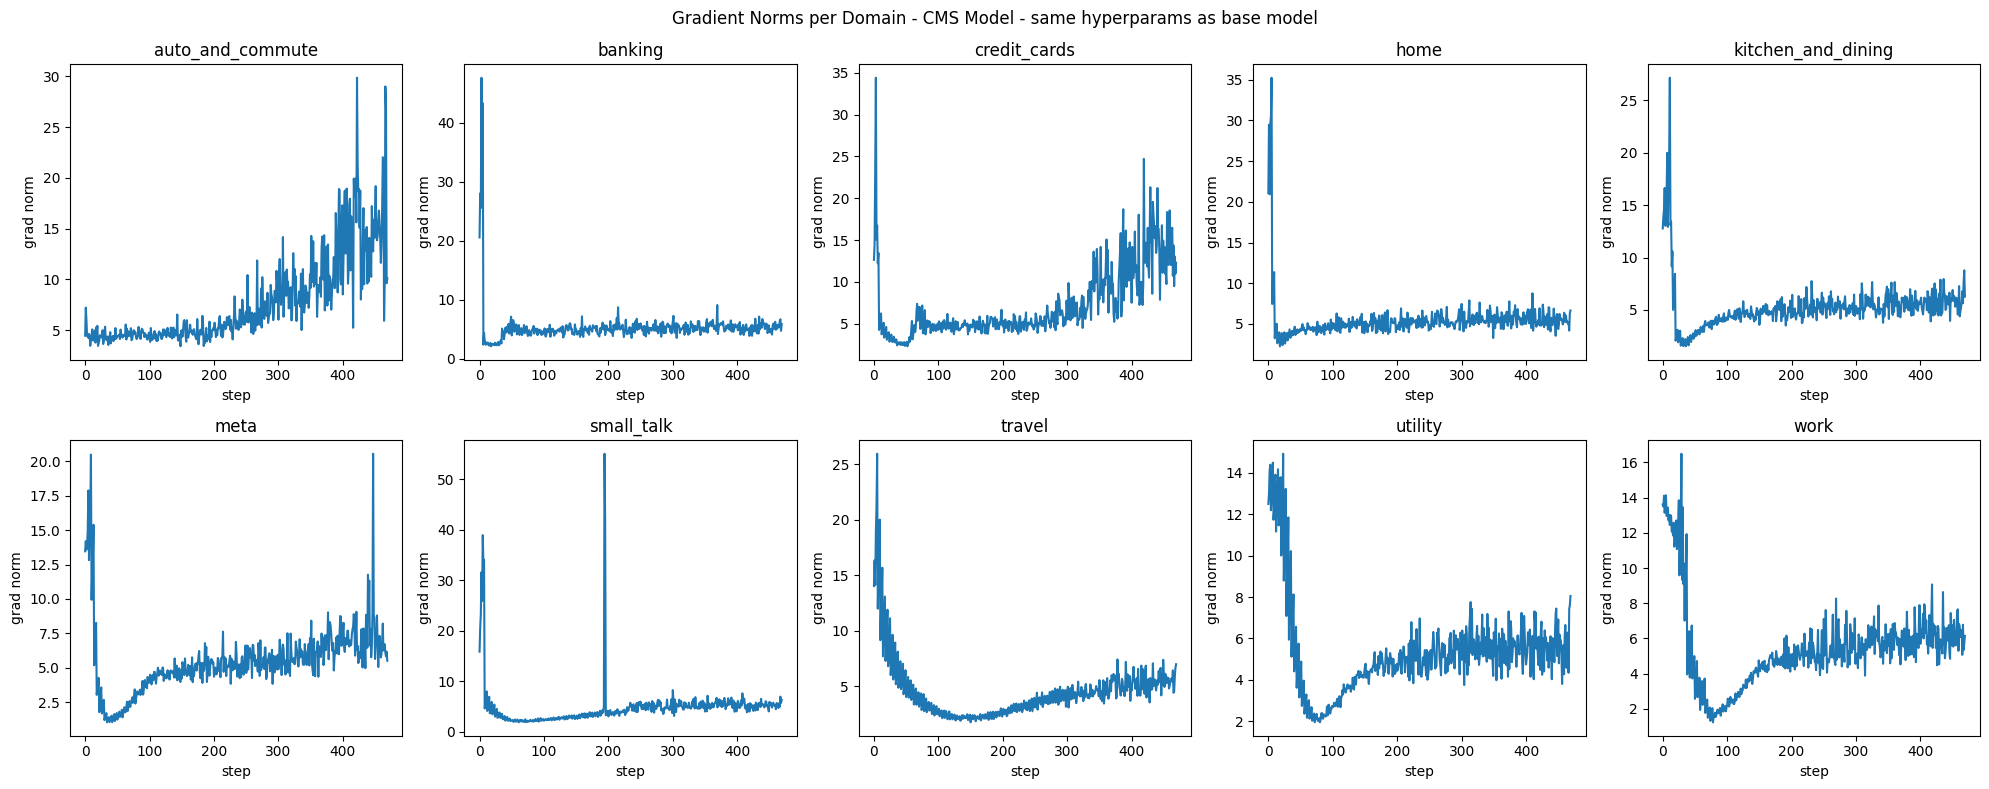

In [47]:
plot_grad_norms(cms_results, 'same hyperparams as base model')

### Experiment 2
- have step counter shared between domains so that chunk sizes to determine when model weights get updated is incremented on between domains since they have optimizer shared.

In [48]:
%%time

cms_bert_2 = setup_cms_bert_model()

# share step counter
cms_results_2 = continual_learning_experiment_with_cms(
        classifier_model=cms_bert_2,
        batched_training_data=train_domains_batched,
        batched_test_data=test_domains_batched,
        _device=device,
        learning_rate=2e-5,
        num_epochs=10,
        shared_steps=True
    )

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.640, Accuracy: 0.0533
Epoch 2, Avg loss: 3.762, Accuracy: 0.0613
Epoch 3, Avg loss: 3.165, Accuracy: 0.0653
Epoch 4, Avg loss: 2.917, Accuracy: 0.0487
Epoch 5, Avg loss: 2.814, Accuracy: 0.0753
Epoch 6, Avg loss: 2.705, Accuracy: 0.1100
Epoch 7, Avg loss: 2.530, Accuracy: 0.1340
Epoch 8, Avg loss: 2.450, Accuracy: 0.1427
Epoch 9, Avg loss: 2.279, Accuracy: 0.1567
Epoch 10, Avg loss: 2.183, Accuracy: 0.1820
Training complete!
Accuracy on auto_and_commute: 22.44
Training on domain 2/10: banking
Epoch 1, Avg loss: 5.226, Accuracy: 0.0247
Epoch 2, Avg loss: 3.601, Accuracy: 0.0807
Epoch 3, Avg loss: 2.871, Accuracy: 0.1007
Epoch 4, Avg loss: 2.722, Accuracy: 0.1033
Epoch 5, Avg loss: 2.682, Accuracy: 0.1113
Epoch 6, Avg loss: 2.659, Accuracy: 0.1087
Epoch 7, Avg loss: 2.656, Accuracy: 0.0920
Epoch 8, Avg loss: 2.656, Accuracy: 0.0940
Epoch 9, Avg loss: 2.647, Accuracy: 0.1047
Epoch 10, Avg loss: 2.654, Accuracy: 0.0960
Training

In [49]:
results_to_pivot(cms_results_2, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,22.444,-,-,-,-,-,-,-,-,-
banking,0.000,9.111,-,-,-,-,-,-,-,-
credit_cards,0.000,0.000,7.333,-,-,-,-,-,-,-
home,0.000,0.000,0.000,6.667,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.000,6.667,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.000,6.667,-,-,-,-
small_talk,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-


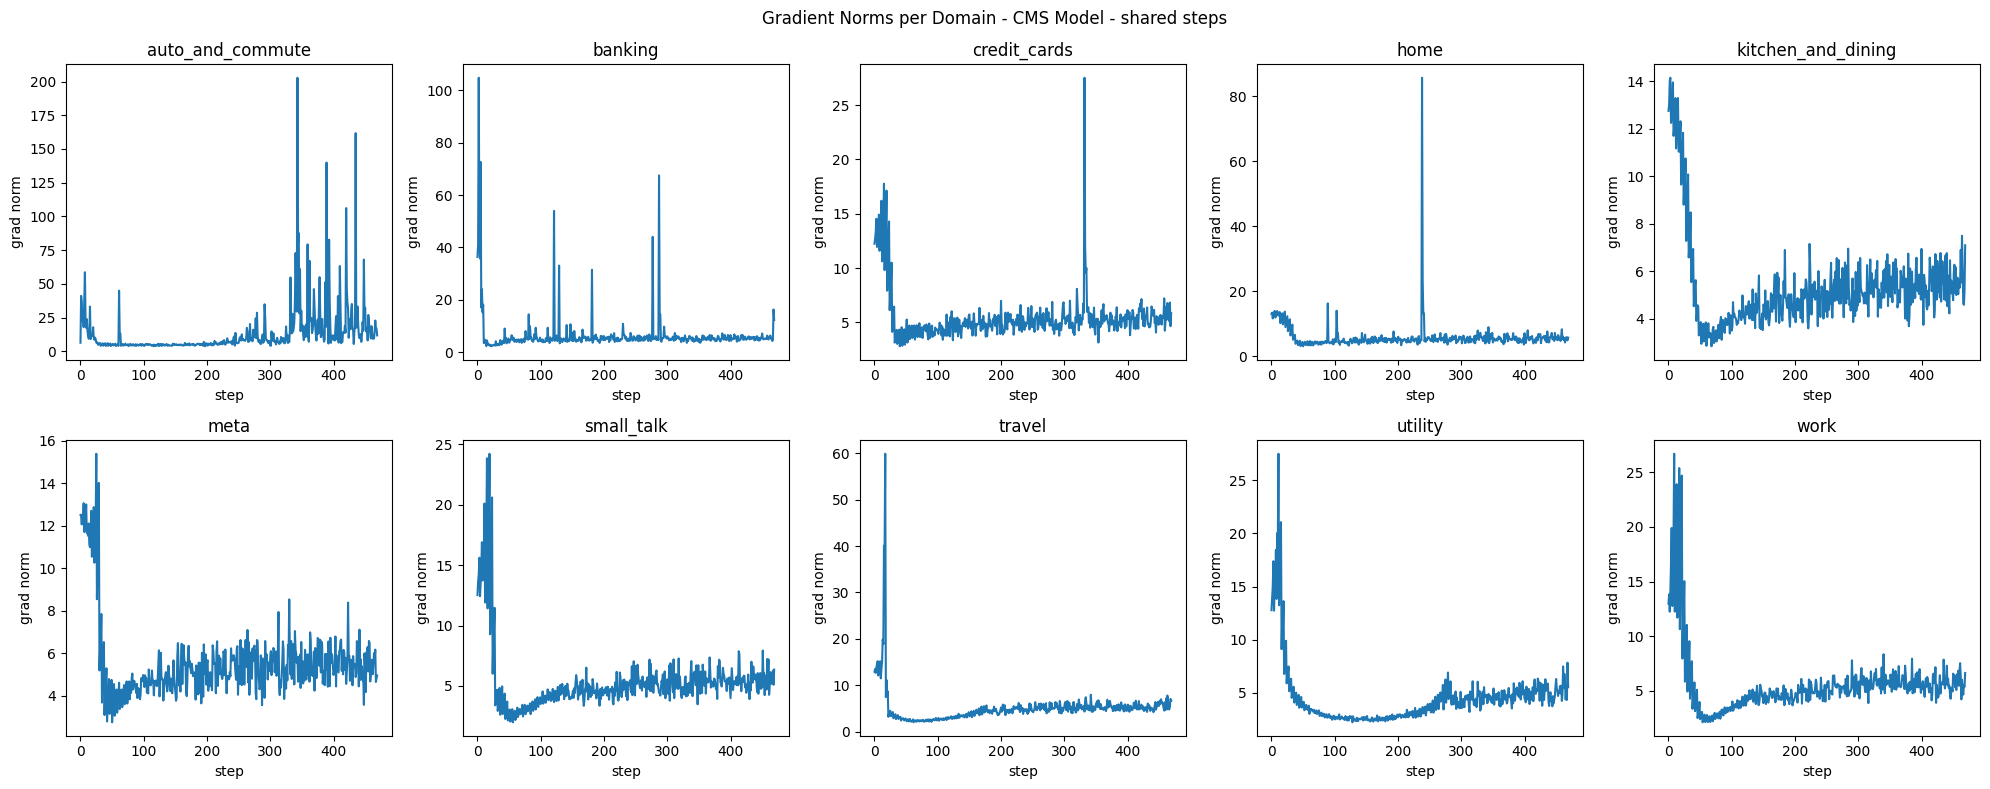

In [50]:
plot_grad_norms(cms_results_2, 'shared steps')

Results: Seems to have improved the accuracy slightly but not done much to improve the gradient norm plots.

### Experiment 3
- shared steps, 25 epochs

In [51]:
%%time

cms_bert_3 = setup_cms_bert_model()

# more epochs and shared steps
cms_results_3 = continual_learning_experiment_with_cms(
        classifier_model=cms_bert_3,
        batched_training_data=train_domains_batched,
        batched_test_data=test_domains_batched,
        _device=device,
        learning_rate=2e-5,
        num_epochs=25,
        shared_steps=True
    )

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.521, Accuracy: 0.0553
Epoch 2, Avg loss: 3.687, Accuracy: 0.0573
Epoch 3, Avg loss: 3.141, Accuracy: 0.0527
Epoch 4, Avg loss: 2.905, Accuracy: 0.0520
Epoch 5, Avg loss: 2.781, Accuracy: 0.1033
Epoch 6, Avg loss: 2.495, Accuracy: 0.1427
Epoch 7, Avg loss: 2.220, Accuracy: 0.2167
Epoch 8, Avg loss: 1.872, Accuracy: 0.3213
Epoch 9, Avg loss: 1.634, Accuracy: 0.3733
Epoch 10, Avg loss: 1.397, Accuracy: 0.4267
Epoch 11, Avg loss: 1.201, Accuracy: 0.5213
Epoch 12, Avg loss: 1.075, Accuracy: 0.5547
Epoch 13, Avg loss: 0.957, Accuracy: 0.6273
Epoch 14, Avg loss: 0.847, Accuracy: 0.6733
Epoch 15, Avg loss: 0.710, Accuracy: 0.7280
Epoch 16, Avg loss: 0.644, Accuracy: 0.7607
Epoch 17, Avg loss: 0.569, Accuracy: 0.7867
Epoch 18, Avg loss: 0.496, Accuracy: 0.8193
Epoch 19, Avg loss: 0.387, Accuracy: 0.8673
Epoch 20, Avg loss: 0.320, Accuracy: 0.8907
Epoch 21, Avg loss: 0.331, Accuracy: 0.8773
Epoch 22, Avg loss: 0.328, Accuracy: 0.8827

In [52]:
results_to_pivot(cms_results_3, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,89.111,-,-,-,-,-,-,-,-,-
banking,0.000,70.222,-,-,-,-,-,-,-,-
credit_cards,0.000,0.000,78.667,-,-,-,-,-,-,-
home,0.000,0.000,3.556,60.222,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.000,78.000,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.667,6.667,-,-,-,-
small_talk,0.000,2.444,0.000,0.000,0.889,0.000,66.222,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,1.778,57.778,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,77.556,-


Results: significant improvement to accuracy results of the current domain. Also see an improvement in continual learning. 25 epochs also appears to be a good stopping point for several of the domains when looking at the loss.

### Experiment 4
- 25 epochs (not shared steps)

In [53]:
%%time

# no shared steps, 25 epochs

cms_bert_4 = setup_cms_bert_model()

cms_results_4 = continual_learning_experiment_with_cms(
        classifier_model=cms_bert_4,
        batched_training_data=train_domains_batched,
        batched_test_data=test_domains_batched,
        _device=device,
        learning_rate=2e-5,
        num_epochs=25,
    )

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.494, Accuracy: 0.0527
Epoch 2, Avg loss: 3.639, Accuracy: 0.0620
Epoch 3, Avg loss: 3.118, Accuracy: 0.0720
Epoch 4, Avg loss: 2.901, Accuracy: 0.0747
Epoch 5, Avg loss: 2.822, Accuracy: 0.0720
Epoch 6, Avg loss: 2.807, Accuracy: 0.0647
Epoch 7, Avg loss: 2.745, Accuracy: 0.0813
Epoch 8, Avg loss: 2.500, Accuracy: 0.1353
Epoch 9, Avg loss: 2.275, Accuracy: 0.1607
Epoch 10, Avg loss: 2.077, Accuracy: 0.2227
Epoch 11, Avg loss: 1.809, Accuracy: 0.2933
Epoch 12, Avg loss: 1.487, Accuracy: 0.4300
Epoch 13, Avg loss: 1.232, Accuracy: 0.5420
Epoch 14, Avg loss: 1.016, Accuracy: 0.6227
Epoch 15, Avg loss: 0.876, Accuracy: 0.6520
Epoch 16, Avg loss: 0.673, Accuracy: 0.7687
Epoch 17, Avg loss: 0.499, Accuracy: 0.8407
Epoch 18, Avg loss: 0.384, Accuracy: 0.8653
Epoch 19, Avg loss: 0.364, Accuracy: 0.8607
Epoch 20, Avg loss: 0.318, Accuracy: 0.8793
Epoch 21, Avg loss: 0.273, Accuracy: 0.9020
Epoch 22, Avg loss: 0.237, Accuracy: 0.9213

In [54]:
results_to_pivot(cms_results_4, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,90.667,-,-,-,-,-,-,-,-,-
banking,2.444,6.667,-,-,-,-,-,-,-,-
credit_cards,0.000,0.000,87.111,-,-,-,-,-,-,-
home,0.000,0.000,10.889,62.444,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.000,10.889,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.000,82.889,-,-,-,-
small_talk,0.000,0.000,0.000,0.000,0.000,13.556,52.222,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,1.556,89.778,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.222,94.667,-


Results: This did better in accuracy for current domain compared to all other experiments. It also appears to have some memory retention better than seen before. But it is still forgetting most of the previous things it learned. Training on more epochs will not help as some of the domains were starting to overfit at 25 epochs.

### Experiment 5
- Adjust the training function such that the number of epochs is dynamic. This will be helpful in potentially getting better results bc not all training domains need the same number of epochs to train.

In [55]:
%%time

# dynamic epochs

cms_bert_5 = setup_cms_bert_model()

# dynamic epochs
cms_results_5 = continual_learning_experiment_with_cms(
        classifier_model=cms_bert_5,
        batched_training_data=train_domains_batched,
        batched_test_data=test_domains_batched,
        _device=device,
        learning_rate=2e-5,
        num_epochs=75,
        patience=4,
        min_delta=0.001 # min change to count as improvement
    )


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.435, Accuracy: 0.0553
Epoch 2, Avg loss: 3.570, Accuracy: 0.0580
Epoch 3, Avg loss: 3.088, Accuracy: 0.0633
Epoch 4, Avg loss: 2.888, Accuracy: 0.0713
Epoch 5, Avg loss: 2.650, Accuracy: 0.1087
Epoch 6, Avg loss: 2.392, Accuracy: 0.1100
Epoch 7, Avg loss: 2.276, Accuracy: 0.1240
Epoch 8, Avg loss: 2.224, Accuracy: 0.1107
Epoch 9, Avg loss: 2.167, Accuracy: 0.1520
Epoch 10, Avg loss: 2.033, Accuracy: 0.1840
Epoch 11, Avg loss: 1.917, Accuracy: 0.2207
Epoch 12, Avg loss: 1.755, Accuracy: 0.2780
Epoch 13, Avg loss: 1.682, Accuracy: 0.2867
Epoch 14, Avg loss: 1.483, Accuracy: 0.3567
Epoch 15, Avg loss: 1.336, Accuracy: 0.4100
Epoch 16, Avg loss: 1.262, Accuracy: 0.4487
Epoch 17, Avg loss: 1.220, Accuracy: 0.4833
Epoch 18, Avg loss: 1.100, Accuracy: 0.5653
Epoch 19, Avg loss: 0.911, Accuracy: 0.6593
Epoch 20, Avg loss: 0.798, Accuracy: 0.7073
Epoch 21, Avg loss: 0.649, Accuracy: 0.7707
Epoch 22, Avg loss: 0.532, Accuracy: 0.8153

In [56]:
results_to_pivot(cms_results_5, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,92.889,-,-,-,-,-,-,-,-,-
banking,0.000,84.667,-,-,-,-,-,-,-,-
credit_cards,0.000,1.556,85.333,-,-,-,-,-,-,-
home,0.000,0.000,0.222,79.556,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.889,88.000,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.000,90.444,-,-,-,-
small_talk,0.000,0.000,0.000,0.000,0.000,4.667,92.889,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,0.000,94.000,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,96.222,-


### Experiment 6
- increase chunking sizes and 25 epochs

In [57]:
%%time

# diff chunking
cms_bert_6 = setup_cms_bert_model(chunk_sizes=[1,4,16]) # still exponential, but increased chunk sizes (so dec freq)

cms_results_6 = continual_learning_experiment_with_cms(
        classifier_model=cms_bert_6,
        batched_training_data=train_domains_batched,
        batched_test_data=test_domains_batched,
        _device=device,
        learning_rate=2e-5,
        num_epochs=25
    )

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.475, Accuracy: 0.0573
Epoch 2, Avg loss: 3.562, Accuracy: 0.0700
Epoch 3, Avg loss: 3.077, Accuracy: 0.0740
Epoch 4, Avg loss: 2.881, Accuracy: 0.0700
Epoch 5, Avg loss: 2.822, Accuracy: 0.0687
Epoch 6, Avg loss: 2.808, Accuracy: 0.0647
Epoch 7, Avg loss: 2.724, Accuracy: 0.1113
Epoch 8, Avg loss: 2.452, Accuracy: 0.2313
Epoch 9, Avg loss: 2.039, Accuracy: 0.3233
Epoch 10, Avg loss: 1.537, Accuracy: 0.5113
Epoch 11, Avg loss: 1.101, Accuracy: 0.6713
Epoch 12, Avg loss: 0.833, Accuracy: 0.7567
Epoch 13, Avg loss: 0.597, Accuracy: 0.8313
Epoch 14, Avg loss: 0.424, Accuracy: 0.8920
Epoch 15, Avg loss: 0.349, Accuracy: 0.9160
Epoch 16, Avg loss: 0.282, Accuracy: 0.9313
Epoch 17, Avg loss: 0.222, Accuracy: 0.9500
Epoch 18, Avg loss: 0.201, Accuracy: 0.9667
Epoch 19, Avg loss: 0.168, Accuracy: 0.9613
Epoch 20, Avg loss: 0.153, Accuracy: 0.9693
Epoch 21, Avg loss: 0.108, Accuracy: 0.9820
Epoch 22, Avg loss: 0.104, Accuracy: 0.9807

In [58]:
results_to_pivot(cms_results_6, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,95.778,-,-,-,-,-,-,-,-,-
banking,4.889,82.889,-,-,-,-,-,-,-,-
credit_cards,2.667,0.000,90.444,-,-,-,-,-,-,-
home,0.000,0.000,0.000,7.111,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.000,6.667,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.000,6.667,-,-,-,-
small_talk,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,6.667,-


### Experiment 7
- decrease learning rate, 25 epochs

In [59]:
%%time

cms_bert_7 = setup_cms_bert_model()

# dec lr, 25 epochs
cms_results_7 = continual_learning_experiment_with_cms(
        classifier_model=cms_bert_7,
        batched_training_data=train_domains_batched,
        batched_test_data=test_domains_batched,
        _device=device,
        learning_rate=5e-6,
        num_epochs=25
    )

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training on domain 1/10: auto_and_commute
Epoch 1, Avg loss: 4.819, Accuracy: 0.0540
Epoch 2, Avg loss: 4.477, Accuracy: 0.0573
Epoch 3, Avg loss: 4.214, Accuracy: 0.0780
Epoch 4, Avg loss: 3.995, Accuracy: 0.0640
Epoch 5, Avg loss: 3.786, Accuracy: 0.0580
Epoch 6, Avg loss: 3.606, Accuracy: 0.0633
Epoch 7, Avg loss: 3.443, Accuracy: 0.0607
Epoch 8, Avg loss: 3.311, Accuracy: 0.0727
Epoch 9, Avg loss: 3.207, Accuracy: 0.0513
Epoch 10, Avg loss: 3.107, Accuracy: 0.0727
Epoch 11, Avg loss: 3.030, Accuracy: 0.0680
Epoch 12, Avg loss: 2.984, Accuracy: 0.0647
Epoch 13, Avg loss: 2.930, Accuracy: 0.0787
Epoch 14, Avg loss: 2.887, Accuracy: 0.0773
Epoch 15, Avg loss: 2.823, Accuracy: 0.0980
Epoch 16, Avg loss: 2.711, Accuracy: 0.1113
Epoch 17, Avg loss: 2.600, Accuracy: 0.1380
Epoch 18, Avg loss: 2.492, Accuracy: 0.1600
Epoch 19, Avg loss: 2.390, Accuracy: 0.1987
Epoch 20, Avg loss: 2.271, Accuracy: 0.2327
Epoch 21, Avg loss: 2.148, Accuracy: 0.2727
Epoch 22, Avg loss: 2.007, Accuracy: 0.3313

In [60]:
results_to_pivot(cms_results_7, DOMAINS)

evaluated_on,auto_and_commute,banking,credit_cards,home,kitchen_and_dining,meta,small_talk,travel,utility,work
trained_on,,,,,,,,,,
auto_and_commute,56.667,-,-,-,-,-,-,-,-,-
banking,0.000,76.000,-,-,-,-,-,-,-,-
credit_cards,0.000,0.000,86.000,-,-,-,-,-,-,-
home,0.000,0.000,4.222,67.111,-,-,-,-,-,-
kitchen_and_dining,0.000,0.000,0.000,0.000,78.222,-,-,-,-,-
meta,0.000,0.000,0.000,0.000,0.222,84.444,-,-,-,-
small_talk,0.000,0.000,0.000,0.222,0.222,7.556,82.444,-,-,-
travel,0.000,0.000,0.000,0.000,0.000,0.000,0.000,95.111,-,-
utility,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,97.111,-


### Other experiments that I tried

- Increased to 100 epochs
  - overtraining
  - consistent loss oscillations after 24 epochs for a few of the domains
  - Note that the rate of loss is not the same between the domains, so having a consistent epoch between all domains does not appear to be ideal for the model's learning/accuracy.
    - This gave rise to the idea of dynamic epochs for training domains.
- Reduce intermediate hidden layer to 32 in MLP of CMS to try to create more of a bottleneck with the hopes that it will converge faster
  - ISSUE: this idea will not work with the way that I have implemented the cms mlp block inits. I based it off of section 7.3 in the paper which talked about init weights coming from a pretrained model as a starting point. Thus, I need the dimensions of the mlp layers to align with DistilBert - so I cannot drop intermediate layer nodes to 32 bc of that (3072 is what the model has).
- Adjust the optimizer initalization code so that the learning rate is divided by the chunk size for that MLP block.
  - The idea was to help stabalize gradients by decreasing learning rate relative to the chunk size. This negativley impacted accuracy. When I thought about it more I realized that this was not faithful to the CMS design and that it was a poor idea, so I did not include it in the notebook.
- I thought about not having a shared optimizer between training runs but I ended up not experimenting with this because I do not think it would make much of an impact (gradient is stored on the param).


## Evaluate and Compare Performance

In [61]:
def results_to_matrix(results, domains):
  """Build R matrix for evaluation functions"""

  T = len(domains)
  # initialize T x T matrix with None
  R = [[None] * T for _ in range(T)]

  for i, train_domain in enumerate(domains):
    for j, eval_domain in enumerate(domains):
      if eval_domain in results[train_domain]:
        R[i][j] = results[train_domain][eval_domain]

  return R

In [63]:
def create_performance_eval_table(experiment_results):

    rows = []

    for experiment_name, results in experiment_results.items():
        R = results_to_matrix(results, DOMAINS)

        bwt = backward_transfer(R)
        acc = average_accuracy(R)
        ada = diagonal_accuracy(R)

        rows.append({
            'Experiment': experiment_name,
            'ADA': round(ada, 4),
            'BWT': round(bwt, 4),
            'ACC': round(acc, 4)
        })

    df = pd.DataFrame(rows)
    return df


experiment_results = {
    'Base - 10 epochs, lr 2e-5, chunk_sizes=[1,2,4]': base_results,
    'CMS - same hyperparams as base': cms_results,
    'CMS - shared step counter': cms_results_2,
    'CMS - 25 epochs': cms_results_4,
    'CMS - 25 epochs, shared step count': cms_results_3,
    'CMS - 25 epochs, lr 5e-6': cms_results_7,
    'CMS - 25 epochs, chunk_size=[1,4,16]': cms_results_6,
    'CMS - dynamic epochs': cms_results_5
}

create_performance_eval_table(experiment_results)


,Experiment,ADA,BWT,ACC
0,"Base - 10 epochs, lr 2e-5, chunk_sizes=[1,2,4]",95.8889,-95.4321,10.0000
1,CMS - same hyperparams as base,19.5111,-20.9383,0.6667
2,CMS - shared step counter,8.5556,-8.7654,0.6667
3,CMS - 25 epochs,62.6222,-64.1481,4.8889
4,"CMS - 25 epochs, shared step count",66.4222,-64.9383,7.9778
5,"CMS - 25 epochs, lr 5e-6",72.9778,-80.3457,0.6667
6,"CMS - 25 epochs, chunk_size=[1,4,16]",31.6222,-34.3951,0.6667
7,CMS - dynamic epochs,89.5778,-89.3333,9.1778


In [64]:
table = create_performance_eval_table(experiment_results)

# make a copy so original is preserved
filtered_table = table.copy()

# drop specific rows by experiment name
rows_to_drop = filtered_table[filtered_table['Experiment'].isin([
    'CMS - same hyperparams as base',
    'CMS - shared step counter',
    'CMS - 25 epochs, lr 5e-6',
    'CMS - 25 epochs, chunk_size=[1,4,16]'
])].index
filtered_table = filtered_table.drop(rows_to_drop)

# sort by specific column — sort by BWT descending (least forgetting first)
sorted_bwt = filtered_table.sort_values(by='BWT', ascending=False)
# reset index after dropping and sorting
sorted_bwt = sorted_bwt.reset_index(drop=True)

# sort by specific column — sort by ACC
sorted_acc = filtered_table.sort_values(by='ACC', ascending=False)
# reset index after dropping and sorting
sorted_acc = sorted_acc.reset_index(drop=True)

# sort by specific column — sort by ADA
sorted_ada = filtered_table.sort_values(by='ADA', ascending=False)
# reset index after dropping and sorting
sorted_ada = sorted_ada.reset_index(drop=True)



In [65]:
from IPython.display import display

print("Sorted by BWT (least forgetting first):")
display(sorted_bwt)

print("\nSorted by ACC (highest retention first):")
display(sorted_acc)

print("\nSorted by ADA (highest peak accuracy first):")
display(sorted_ada)

Sorted by BWT (least forgetting first):


,Experiment,ADA,BWT,ACC
0,CMS - 25 epochs,62.6222,-64.1481,4.8889
1,"CMS - 25 epochs, shared step count",66.4222,-64.9383,7.9778
2,CMS - dynamic epochs,89.5778,-89.3333,9.1778
3,"Base - 10 epochs, lr 2e-5, chunk_sizes=[1,2,4]",95.8889,-95.4321,10.0000



Sorted by ACC (highest retention first):


,Experiment,ADA,BWT,ACC
0,"Base - 10 epochs, lr 2e-5, chunk_sizes=[1,2,4]",95.8889,-95.4321,10.0000
1,CMS - dynamic epochs,89.5778,-89.3333,9.1778
2,"CMS - 25 epochs, shared step count",66.4222,-64.9383,7.9778
3,CMS - 25 epochs,62.6222,-64.1481,4.8889



Sorted by ADA (highest peak accuracy first):


,Experiment,ADA,BWT,ACC
0,"Base - 10 epochs, lr 2e-5, chunk_sizes=[1,2,4]",95.8889,-95.4321,10.0000
1,CMS - dynamic epochs,89.5778,-89.3333,9.1778
2,"CMS - 25 epochs, shared step count",66.4222,-64.9383,7.9778
3,CMS - 25 epochs,62.6222,-64.1481,4.8889


## Relevant sources while coding:
- Dataset Library - Huggingface: https://huggingface.co/docs/datasets/package_reference/main_classes
- DistilBert model: https://huggingface.co/docs/transformers/model_doc/distilbert?usage=AutoModel
- Claude
- PyTorch documentation
- Any other links I cited in markdown in this notebook